# Stroke Generation Model

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional, Tuple, Sequence, List, Dict, Any
import os
from scipy import stats
import yaml

from dataclasses import dataclass, field
from scipy.special import erf
import torch
import torch.nn as nn
from torch.nn.init import xavier_uniform
import torch.nn.functional as F
from torch.distributions import Categorical, MultivariateNormal
from torch.utils.data import Dataset, DataLoader

## Stroke

In [2]:
STROKE_TIME_COLS = ['mu', 'sigma', 't0']
STROKE_GEOM_COLS = ['delta_p', 'u_e', 'lambda_e', 'u_s', 'lambda_s']
ARRAY_COLS = ['delta_p', 'u_s', 'u_e']
DATABASE_ROOT = os.getcwd().split('src')[0] + 'reconstructed_csv'
EPS = 1e-12

## Nework Architecture

### Mixture Density Network Head

In [3]:

class MixtureDensityNetwork(nn.Module):
    """
    MDN head with full-covariance Gaussian components.
    Outputs: means [B, K, D], lower Cholesky factors [B, K, D, D], mixing logits [B, K].
    """

    def __init__(self, input_dim, output_dim, num_components, hidden_dim=128, min_diag=1e-3):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.num_components = num_components
        self.hidden_dim = hidden_dim
        self.min_diag = min_diag
        self.num_tril = output_dim * (output_dim + 1) // 2

        rows, cols = torch.tril_indices(output_dim, output_dim)
        self.register_buffer("tril_rows", rows, persistent=False)
        self.register_buffer("tril_cols", cols, persistent=False)
        self.register_buffer("diag_mask", rows == cols, persistent=False)

        self.hidden_layer = nn.Linear(input_dim, hidden_dim)
        self.weights_layer = nn.Linear(hidden_dim, num_components)  # mixing logits
        self.means_layer = nn.Linear(hidden_dim, num_components * output_dim)
        self.scale_layer = nn.Linear(hidden_dim, num_components * self.num_tril)

    def set_weights(self, target_samples: torch.Tensor, sigma_weight_scale: float = 0.1):
        """
        Initialization. `target_samples` [N, D] should already be standardized.
        Means are spread over the target range; each Cholesky factor starts as
        diag(std_d) with zero off-diagonal entries.
        """
        nn.init.kaiming_uniform_(self.hidden_layer.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden_layer.bias)

        nn.init.xavier_uniform_(self.weights_layer.weight)
        nn.init.xavier_uniform_(self.means_layer.weight)
        nn.init.xavier_uniform_(self.scale_layer.weight)

        t_min = target_samples.min(dim=0).values  # [D]
        t_max = target_samples.max(dim=0).values  # [D]
        mean_bias = torch.empty(self.num_components, self.output_dim)
        for k in range(self.num_components):
            mean_bias[k] = (t_min + (t_max - t_min) * (k + 0.5) / self.num_components).cpu()

        with torch.no_grad():
            self.means_layer.bias.copy_(mean_bias.reshape(-1))
            self.scale_layer.weight.mul_(sigma_weight_scale)

            # inverse softplus so that diag(L) starts at the per-dimension data std
            data_std = target_samples.std(dim=0).to(self.scale_layer.bias)
            init_diag = (data_std - self.min_diag).clamp_min(1e-3)
            raw_diag = torch.log(torch.expm1(init_diag))
            bias = torch.zeros(self.num_components, self.num_tril).to(self.scale_layer.bias)
            bias[:, self.diag_mask] = raw_diag
            self.scale_layer.bias.copy_(bias.reshape(-1))

    def _build_scale_tril(self, raw: torch.Tensor) -> torch.Tensor:
        """raw [B, K, m] -> lower-triangular L [B, K, D, D] with positive diagonal."""
        batch = raw.size(0)
        dim = self.output_dim
        tril = raw.new_zeros(batch, self.num_components, dim, dim)
        tril[..., self.tril_rows, self.tril_cols] = raw
        diag = F.softplus(tril.diagonal(dim1=-2, dim2=-1)) + self.min_diag
        return tril.tril(-1) + torch.diag_embed(diag)

    def forward(self, x: torch.Tensor):
        hidden = torch.relu(self.hidden_layer(x))
        mix_logits = self.weights_layer(hidden)
        means = self.means_layer(hidden).view(-1, self.num_components, self.output_dim)
        raw = self.scale_layer(hidden).view(-1, self.num_components, self.num_tril)
        return means, self._build_scale_tril(raw), mix_logits

### Full Model Architecture

In [4]:
class GenerativeModel(nn.Module):
    """Generative model of strokes: embeddings -> LSTM -> trunk -> full-covariance MDN."""

    def __init__(self, input_dim, embedding_dim, LSTM_dim, LSTM_count, output_dim,
                 mixture_components, recur_dim=None, min_diag=1e-3):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.embedding_dim = embedding_dim
        self.lstm_dim = LSTM_dim
        self.lstm_count = LSTM_count
        self.mixture_components = mixture_components
        # dimension of the previous-step vector (defaults to the target dimension)
        self.recur_dim = output_dim if recur_dim is None else recur_dim

        self.input_embedding = nn.Linear(input_dim, embedding_dim)
        self.recur_embedding = nn.Linear(self.recur_dim, embedding_dim)
        self.lstm = nn.LSTM(input_size=embedding_dim * 2, hidden_size=LSTM_dim,
                            num_layers=LSTM_count, batch_first=True)
        self.trunk = nn.Linear(LSTM_dim, LSTM_dim)
        self.mdn = MixtureDensityNetwork(LSTM_dim, output_dim,
                                         num_components=mixture_components, min_diag=min_diag)

    def set_weights(self, target_samples, sigma_weight_scale=0.1):
        self.mdn.set_weights(target_samples, sigma_weight_scale)
        for layer in (self.input_embedding, self.recur_embedding, self.trunk):
            nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)

    def forward(self, x, prev_output=None, state=None, return_state=False):
        """
        Args:
            x: conditioning input [B, input_dim]
            prev_output: previous-step vector [B, recur_dim] (zeros embedding if None)
            state: optional LSTM state (h, c) carried across calls; None resets it
        Returns:
            means [B, K, D], scale_tril [B, K, D, D], mix_logits [B, K] (+ state if requested)
        """
        input_embedded = self.input_embedding(x)
        if prev_output is not None:
            prev_embedded = self.recur_embedding(prev_output)
        else:
            prev_embedded = torch.zeros_like(input_embedded)

        combined = torch.cat((input_embedded, prev_embedded), dim=-1)
        lstm_out, new_state = self.lstm(combined.unsqueeze(1), state)  # sequence length 1
        trunk_out = torch.relu(self.trunk(lstm_out.squeeze(1)))

        means, scale_tril, mix_logits = self.mdn(trunk_out)
        if return_state:
            return means, scale_tril, mix_logits, new_state
        return means, scale_tril, mix_logits

    @torch.no_grad()
    def sample(self, x, prev_output=None, state=None):
        means, scale_tril, mix_logits = self.forward(x, prev_output, state)
        batch_idx = torch.arange(means.size(0), device=means.device)
        comp_idx = Categorical(logits=mix_logits).sample()
        sel_mean = means[batch_idx, comp_idx]          # [B, D]
        sel_tril = scale_tril[batch_idx, comp_idx]     # [B, D, D]
        eps = torch.randn_like(sel_mean)
        return sel_mean + (sel_tril @ eps.unsqueeze(-1)).squeeze(-1)



## Loss

In [5]:
def duplication_matrix(dim: int, device=None, dtype=None) -> torch.Tensor:
    """
    Duplication matrix Dup such that vec(S) = Dup @ vech(S) for any symmetric S.
    Shape: [dim * dim, dim * (dim + 1) // 2]. Row-major vec, lower-triangle vech.
    """
    rows, cols = torch.tril_indices(dim, dim, device=device)
    n_free = rows.numel()
    dup = torch.zeros(dim * dim, n_free, device=device, dtype=dtype)
    col_idx = torch.arange(n_free, device=device)
    dup[rows * dim + cols, col_idx] = 1.0
    dup[cols * dim + rows, col_idx] = 1.0
    return dup


def gaussian_fisher(sigma: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Explicit Fisher information blocks of N(mu, Sigma).

    Args:
        sigma: covariance matrices, shape [..., D, D].
    Returns:
        fisher_mu:    [..., D, D]   = Sigma^-1
        fisher_sigma: [..., m, m]   = 1/2 Dup^T (Sigma^-1 (x) Sigma^-1) Dup, m = D(D+1)/2
    """
    dim = sigma.size(-1)
    dup = duplication_matrix(dim, sigma.device, sigma.dtype)
    sigma_inv = torch.linalg.inv(sigma)
    kron = torch.einsum("...ij,...kl->...ikjl", sigma_inv, sigma_inv)
    kron = kron.reshape(*sigma.shape[:-2], dim * dim, dim * dim)
    fisher_sigma = 0.5 * dup.T @ kron @ dup
    return sigma_inv, fisher_sigma


def gaussian_fisher_matrix(sigma: torch.Tensor) -> torch.Tensor:
    """Full block-diagonal Fisher matrix over (mu, vech(Sigma)), shape [..., D+m, D+m]."""
    fisher_mu, fisher_sigma = gaussian_fisher(sigma)
    dim, n_free = fisher_mu.size(-1), fisher_sigma.size(-1)
    full = sigma.new_zeros(*sigma.shape[:-2], dim + n_free, dim + n_free)
    full[..., :dim, :dim] = fisher_mu
    full[..., dim:, dim:] = fisher_sigma
    return full


def gaussian_natural_gradient(
    diff: torch.Tensor,
    sigma: torch.Tensor,
    resp: torch.Tensor,
    explicit_fisher: bool = False,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Complete-data natural gradient of resp * log N(y; mu, Sigma) w.r.t. (mu, vech(Sigma)).

    Args:
        diff:  y - mu, shape [..., D]
        sigma: covariance, shape [..., D, D]
        resp:  responsibilities, shape [...]
        explicit_fisher: if True, build the Fisher blocks explicitly and solve F x = grad
            (O(D^6) per component: use it to validate, not for training).
            If False, use the equivalent closed form.
    Returns:
        nat_mu:    [..., D]
        nat_sigma: [..., m]  (vech coordinates)
    """
    dim = diff.size(-1)
    rows, cols = torch.tril_indices(dim, dim, device=diff.device)
    outer = diff.unsqueeze(-1) * diff.unsqueeze(-2)  # d d^T

    if not explicit_fisher:
        nat_mu = resp.unsqueeze(-1) * diff
        nat_sigma = resp[..., None, None] * (outer - sigma)
        return nat_mu, nat_sigma[..., rows, cols]

    fisher_mu, fisher_sigma = gaussian_fisher(sigma)
    sigma_inv = fisher_mu
    dup = duplication_matrix(dim, diff.device, diff.dtype)

    grad_mu = resp.unsqueeze(-1) * (sigma_inv @ diff.unsqueeze(-1)).squeeze(-1)
    # symmetric matrix derivative of resp * log N w.r.t. Sigma
    grad_mat = 0.5 * resp[..., None, None] * (sigma_inv @ outer @ sigma_inv - sigma_inv)
    grad_vech = torch.einsum("pm,...p->...m", dup, grad_mat.reshape(*sigma.shape[:-2], dim * dim))

    nat_mu = torch.linalg.solve(fisher_mu, grad_mu.unsqueeze(-1)).squeeze(-1)
    nat_sigma = torch.linalg.solve(fisher_sigma, grad_vech.unsqueeze(-1)).squeeze(-1)
    return nat_mu, nat_sigma


def categorical_natural_gradient(
    resp: torch.Tensor, pi: torch.Tensor, pi_floor: float = 1e-4
) -> torch.Tensor:
    """
    Natural gradient of sum_k r_k log pi_k w.r.t. the softmax logits.
    The Fisher matrix diag(pi) - pi pi^T is singular; r / pi solves F x = r - pi, and the
    mean is removed (softmax is invariant to a constant shift of the logits).
    `pi_floor` avoids huge steps when a component has a vanishing weight.
    """
    ratio = resp / pi.clamp_min(pi_floor)
    return ratio - ratio.mean(dim=-1, keepdim=True)

In [6]:
def ngem_loss(
    model,
    batch,
    device,
    fisher_mode: str = "closed_form",
    natural_mixing: bool = True,
    pi_floor: float = 1e-4,
    return_nll: bool = False,
):
    """
    Multivariate (full covariance) nGEM surrogate loss.

    E-step: responsibilities from the current parameters (no gradient).
    M-step: the complete-data natural gradient w.r.t. the network outputs
            (means, vech(Sigma), mixing logits) is computed with the Fisher blocks of
            each component and injected into backprop through a surrogate loss, so that
            d(loss)/d(output) = -natural_gradient / batch_size.

    Args:
        fisher_mode: "closed_form" (fast) or "explicit" (builds and solves the Fisher
            blocks; use it for validation).
        natural_mixing: natural gradient for the mixing logits (True) or plain gradient
            r - pi (False).
        pi_floor: lower clamp on pi in the categorical natural gradient.
        return_nll: also return the mixture NLL (detached) for monitoring.
    """
    if fisher_mode not in ("closed_form", "explicit"):
        raise ValueError("fisher_mode must be 'closed_form' or 'explicit'")

    wp = batch["wp"].to(device)
    wp_n = batch["wp_n"].to(device)
    prev_t0 = batch["prev_t0"].to(device)
    prev_mu = batch["prev_mu"].to(device)
    prev_sigma = batch["prev_sigma"].to(device)
    prev_theta = batch["prev_theta"].to(device)
    prev_psi = batch["prev_psi"].to(device)
    t0 = batch["t0"].to(device)
    mu = batch["mu"].to(device)
    sigma = batch["sigma"].to(device)

    # target vector [B, D]
    target = torch.cat([t0, mu, sigma, batch["p_m"].to(device), batch["p_e"].to(device)], dim=-1)
    input_data = torch.cat([wp, wp_n], dim=-1)
    prev_input = torch.cat([prev_t0, prev_mu, prev_sigma, prev_theta, prev_psi], dim=-1)

    means, scale_tril, mix_logits = model(input_data, prev_output=prev_input)
    batch_size, dim = target.shape

    # ---- E-step (no gradient) ----
    with torch.no_grad():
        dist = MultivariateNormal(loc=means.detach(), scale_tril=scale_tril.detach())
        log_prob = dist.log_prob(target.unsqueeze(1))                  # [B, K]
        log_joint = F.log_softmax(mix_logits.detach(), dim=-1) + log_prob
        resp = torch.softmax(log_joint, dim=-1)                        # [B, K]
        nll = -torch.logsumexp(log_joint, dim=-1).mean()
        pi = torch.softmax(mix_logits.detach(), dim=-1)

    # ---- M-step: natural gradients w.r.t. the network outputs ----
    diff = (target.unsqueeze(1) - means).detach()                      # [B, K, D]
    cov = scale_tril @ scale_tril.transpose(-1, -2)                    # Sigma = L L^T (with grad)
    rows, cols = torch.tril_indices(dim, dim, device=target.device)
    cov_vech = cov[..., rows, cols]                                    # [B, K, m]

    nat_mu, nat_cov = gaussian_natural_gradient(
        diff, cov.detach(), resp, explicit_fisher=(fisher_mode == "explicit")
    )
    nat_pi = categorical_natural_gradient(resp, pi, pi_floor) if natural_mixing else resp - pi

    # Surrogate: its gradient w.r.t. (means, vech(Sigma), logits) is minus the natural
    # gradient; autograd then applies the Jacobian (chain rule) down to the weights.
    # Note: vech coordinates (lower triangle only) are used on purpose, so that the
    # off-diagonal entries of Sigma are not counted twice.
    surrogate = (
        (means * nat_mu).sum()
        + (cov_vech * nat_cov).sum()
        + (mix_logits * nat_pi).sum()
    )
    loss = -surrogate / batch_size

    if return_nll:
        return loss, nll
    return loss

## Dataset
Define the classes

In [7]:
class StrokeDataset(Dataset):
    """
    A custom dataset class for loading stroke data from a pandas DataFrame
    """
    def __init__(self, data_frame: pd.DataFrame):
        """
        Args:
            data_frame (pd.DataFrame): The DataFrame containing the stroke data.
        """
        self.data_frame = data_frame

    def __len__(self):
        return len(self.data_frame)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        item_dict = {
            'delta_wp': torch.tensor(self.data_frame.iloc[idx]['wp'], dtype=torch.float32),
            'delta_wp_n': torch.tensor(self.data_frame.iloc[idx]['wp_n'], dtype=torch.float32),
        }

        for col in STROKE_GEOM_COLS + STROKE_TIME_COLS:
            item_dict[col] = torch.tensor(self.data_frame.iloc[idx][col], dtype=torch.float32)

        for col in STROKE_GEOM_COLS:
            item_dict[f'prev_{col}'] = torch.tensor(self.data_frame.iloc[idx][f'prev_{col}'], dtype=torch.float32)

        return item_dict

In [8]:
class StrokeDataLoader(DataLoader):
    """
    A custom DataLoader class for loading stroke data.
    """
    def __init__(self, dataset: StrokeDataset, batch_size: int = 32, shuffle: bool = True, num_workers: int = 0):
        """
        Args:
            dataset (StrokeDataset): The dataset to load.
            batch_size (int): Number of samples per batch.
            shuffle (bool): Whether to shuffle the data at every epoch.
            num_workers (int): How many subprocesses to use for data loading.
        """
        super(StrokeDataLoader, self).__init__(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)

In [9]:
def create_database(root:str) -> pd.DataFrame:
    """
    Create a database of stroke parameters from CSV files in the given root directory.

    Args:
        root (str): The root directory containing CSV files.
    Returns:
        database (pd.DataFrame): Dafaframe representation of the dataset
    """
    root_folder = os.path.abspath(os.path.join(os.getcwd(), root))
    records = []

    for subject_folder in os.listdir(root_folder):
        if not os.path.isdir(os.path.join(root_folder, subject_folder)):
            continue
        subject_name = os.path.basename(subject_folder)

        for task_folder in os.listdir(os.path.join(root_folder, subject_folder)):
            if not os.path.isdir(os.path.join(root_folder, subject_folder, task_folder)):
                continue
            task_name = os.path.basename(task_folder)

            for csv_file in os.listdir(os.path.join(root_folder, subject_folder, task_folder)):
                if os.path.isdir(os.path.join(root_folder, subject_folder, task_folder, csv_file)):
                    continue
                csv_path = os.path.join(root_folder, subject_folder, task_folder, csv_file)
                recording_number = int(os.path.basename(csv_file).split('_')[1].split('.')[0])  # Assuming the format is 'recording_X.csv'
                stroke_data = pd.read_csv(csv_path)

                for _, row in stroke_data.iterrows():
                    record = {
                        'subject': subject_name,
                        'task': task_name,
                        'recording': recording_number,
                        'stroke_number': int(row['stroke_id']),
                    }
                    for col in STROKE_TIME_COLS + STROKE_GEOM_COLS:
                        record[col] = row[col]

                    for col in ARRAY_COLS:
                        record[col] = [float(x) for x in row[col].split(';')]
                    records.append(record)
            

    subject_names = sorted({record["subject"] for record in records})
    subject_map = {
        name: f"S{index:02d}"
        for index, name in enumerate(subject_names, start=1)
    }

    for record in records:
        record["subject"] = subject_map[record["subject"]]

    return pd.DataFrame(records)
database = create_database(DATABASE_ROOT)


### Data preprocessing
Couple each stroke with its previous one, when available.

In [10]:
coupled_database = database.merge(
    database,
    on=['subject', 'task', 'recording'],
    how='outer',
    suffixes=('', '_previous')
)
coupled_database = coupled_database[
    (coupled_database['stroke_number'] == coupled_database['stroke_number_previous'] + 1)
    | (coupled_database['stroke_number'] == 0)
]
previous_cols = [col for col in coupled_database.columns if col.endswith("_previous")]
coupled_database.loc[coupled_database["stroke_number"].eq(0), previous_cols] = None
# Convert list-like values to hashable tuples before deduplicating.
for col in coupled_database.columns:
    if coupled_database[col].map(lambda v: isinstance(v, (list, tuple, np.ndarray))).any():
        coupled_database[col] = coupled_database[col].map(
            lambda v: tuple(np.asarray(v, dtype=float).ravel().tolist())
            if isinstance(v, (list, tuple, np.ndarray))
            else v
        )

coupled_database = coupled_database.drop_duplicates().reset_index(drop=True)

Extract and compute the $\Delta wp$

In [11]:
PATH_TO_PATHS_FILE = os.path.join(os.getcwd(), '..', '..', '..', 'unisa_acg_ros2', 'haptics', 'haptic_interaction_teach_and_record_demo', 'config', 'paths.yaml')
if not os.path.exists(PATH_TO_PATHS_FILE):
    raise FileNotFoundError(f"Paths file not found: {PATH_TO_PATHS_FILE}")


WS_MIN = np.array([-0.082, -0.065, -0.085])
WS_MAX = np.array([0.082, 0.065, 0.085])

def waypoints_to_array(waypoints, swap_yz=False, ws_min=WS_MIN, ws_max=WS_MAX):
    """Convert the list of {'x','y','z'} dicts (normalized) into an Nx3 array in device coordinates."""
    arr = np.array([[w["x"], w["y"], w["z"]] for w in waypoints], dtype=float)
    if swap_yz:
        arr[:, [1, 2]] = arr[:, [2, 1]]
    if ws_min is not None and ws_max is not None:
        ws_min = np.asarray(ws_min, dtype=float)
        ws_max = np.asarray(ws_max, dtype=float)
        arr = ws_min + arr * (ws_max - ws_min)
    return arr

WAYPOINTS_BY_TASK = {}
with open(PATH_TO_PATHS_FILE, 'r') as f:
    paths_data = yaml.safe_load(f)
    print(f"Loaded paths data: {paths_data['paths']}")

    for path in paths_data['paths']:
        WAYPOINTS_BY_TASK[path['name']] = waypoints_to_array(path['waypoints'])

WAYPOINTS_BY_TASK = {
    task: waypoints - waypoints[0]
    for task, waypoints in WAYPOINTS_BY_TASK.items()
}

WAYPOINTS_BY_TASK

Loaded paths data: [{'name': 'BURSTs_XY', 'waypoints': [{'x': 0.2, 'y': 0.2, 'z': 0.5}, {'x': 0.8, 'y': 0.8, 'z': 0.5}]}, {'name': 'BURSTs_XZ', 'waypoints': [{'x': 0.2, 'y': 0.5, 'z': 0.2}, {'x': 0.8, 'y': 0.5, 'z': 0.8}]}, {'name': 'BURSTs_YZ', 'waypoints': [{'x': 0.5, 'y': 0.2, 'z': 0.2}, {'x': 0.5, 'y': 0.8, 'z': 0.8}]}, {'name': 'BURSTc_XY', 'waypoints': [{'x': 0.1, 'y': 0.2, 'z': 0.5}, {'x': 0.9, 'y': 0.5, 'z': 0.5}, {'x': 0.1, 'y': 0.8, 'z': 0.5}]}, {'name': 'BURSTc_XZ', 'waypoints': [{'x': 0.2, 'y': 0.5, 'z': 0.1}, {'x': 0.5, 'y': 0.5, 'z': 0.9}, {'x': 0.8, 'y': 0.5, 'z': 0.1}]}, {'name': 'BURSTc_YZ', 'waypoints': [{'x': 0.5, 'y': 0.1, 'z': 0.2}, {'x': 0.5, 'y': 0.9, 'z': 0.5}, {'x': 0.5, 'y': 0.1, 'z': 0.8}]}, {'name': 'REVERSAL_Z', 'waypoints': [{'x': 0.5, 'y': 0.5, 'z': 0.15}, {'x': 0.5, 'y': 0.5, 'z': 0.85}, {'x': 0.55, 'y': 0.5, 'z': 0.15}]}, {'name': 'REVERSAL_3D', 'waypoints': [{'x': 0.15, 'y': 0.2, 'z': 0.3}, {'x': 0.85, 'y': 0.8, 'z': 0.7}, {'x': 0.25, 'y': 0.75, 'z': 0

{'BURSTs_XY': array([[0.    , 0.    , 0.    ],
        [0.0984, 0.078 , 0.    ]]),
 'BURSTs_XZ': array([[0.    , 0.    , 0.    ],
        [0.0984, 0.    , 0.102 ]]),
 'BURSTs_YZ': array([[0.   , 0.   , 0.   ],
        [0.   , 0.078, 0.102]]),
 'BURSTc_XY': array([[0.    , 0.    , 0.    ],
        [0.1312, 0.039 , 0.    ],
        [0.    , 0.078 , 0.    ]]),
 'BURSTc_XZ': array([[0.    , 0.    , 0.    ],
        [0.0492, 0.    , 0.136 ],
        [0.0984, 0.    , 0.    ]]),
 'BURSTc_YZ': array([[0.   , 0.   , 0.   ],
        [0.   , 0.104, 0.051],
        [0.   , 0.   , 0.102]]),
 'REVERSAL_Z': array([[0.    , 0.    , 0.    ],
        [0.    , 0.    , 0.119 ],
        [0.0082, 0.    , 0.    ]]),
 'REVERSAL_3D': array([[0.    , 0.    , 0.    ],
        [0.1148, 0.078 , 0.068 ],
        [0.0164, 0.0715, 0.0085]]),
 'CHECK_XY': array([[ 0.    ,  0.    ,  0.    ],
        [ 0.041 , -0.0455,  0.    ],
        [ 0.123 ,  0.0455,  0.    ]]),
 'CHECK_XZ': array([[ 0.    ,  0.    ,  0.    ],
    

Normalize the $\Delta wp$ by assuming $(0,0,0)$ as the origin, for each stroke.

In [12]:
coupled_database["wp"] = coupled_database.apply(
  lambda row: np.asarray(
    WAYPOINTS_BY_TASK[row["task"]][min([int(row["stroke_number"]) + 1, len(WAYPOINTS_BY_TASK[row["task"]]) - 1])],
    dtype=np.float32,
  ),
  axis=1,
)

coupled_database["wp_n"] = coupled_database.apply(
  lambda row: np.asarray(
    WAYPOINTS_BY_TASK[row["task"]][min([int(row["stroke_number"]) + 2, len(WAYPOINTS_BY_TASK[row["task"]]) - 1])],
    dtype=np.float32,
  ),
  axis=1,
)

def subtract_previous_delta(row, column):
  previous_delta = row["delta_p_previous"]
  if previous_delta is None or (
    isinstance(previous_delta, float) and np.isnan(previous_delta)
  ):
    previous_delta = np.zeros(3, dtype=np.float32)
  return np.asarray(row[column], dtype=np.float32) - np.asarray(
    previous_delta, dtype=np.float32
  )

final_database = coupled_database.copy()

final_database["wp"] = final_database.apply(
  lambda row: subtract_previous_delta(row, "wp"),
  axis=1,
)

final_database["wp_n"] = final_database.apply(
  lambda row: subtract_previous_delta(row, "wp_n"),
  axis=1,
)
final_database = final_database.drop(columns="delta_p_previous")

final_database.head(10)


,subject,task,recording,stroke_number,mu,sigma,t0,delta_p,u_e,lambda_e,...,stroke_number_previous,mu_previous,sigma_previous,t0_previous,u_e_previous,lambda_e_previous,u_s_previous,lambda_s_previous,wp,wp_n
0,S01,BURSTc_XY,0,0,0.153586,0.081711,-0.642,"(0.14432144911670713, 0.06706838777927969, -0....","(0.2207562287564279, 0.9723969202238582, 0.075...",0.060210,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
1,S01,BURSTc_XY,0,1,-0.680848,0.182883,0.294,"(-0.1601478798257494, 0.08058505759973233, 0.0...","(-0.9995785545264549, -0.02794476200820617, -0...",0.028732,...,0.0,0.153586,0.081711,-0.642,"(0.2207562287564279, 0.9723969202238582, 0.075...",0.060210,"(0.9700483590091524, -0.2362519799379216, -0.0...",0.033370,"[-0.14432146, 0.010931611, 0.012907238]","[-0.14432146, 0.010931611, 0.012907238]"
2,S01,BURSTc_XY,1,0,-0.295600,0.138464,-0.240,"(0.17056932130531882, 0.060494883362214404, -0...","(0.2871657581466427, 0.9575315413899897, 0.025...",0.066373,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
3,S01,BURSTc_XY,1,1,-0.580980,0.181585,0.254,"(-0.1849465689957268, 0.08243738313551789, -0....","(-0.9705440395631034, -0.14308890984005446, 0....",0.058829,...,0.0,-0.295600,0.138464,-0.240,"(0.2871657581466427, 0.9575315413899897, 0.025...",0.066373,"(0.9847971472621677, -0.14958862537256923, 0.0...",0.026934,"[-0.17056932, 0.017505117, 0.0053005563]","[-0.17056932, 0.017505117, 0.0053005563]"
4,S01,BURSTc_XY,2,0,0.107258,0.089652,-0.618,"(0.14651876924533025, 0.06354141825907234, -0....","(0.19773841109482437, 0.9793110041111769, 0.04...",0.060777,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
5,S01,BURSTc_XY,2,1,-0.637087,0.184532,0.258,"(-0.16339250686681103, 0.08152290983928898, -0...","(-0.9911391905463522, -0.12794444918787315, 0....",0.047799,...,0.0,0.107258,0.089652,-0.618,"(0.19773841109482437, 0.9793110041111769, 0.04...",0.060777,"(0.9240205645838965, -0.3809984546984475, -0.0...",0.039859,"[-0.14651877, 0.014458582, 0.013137617]","[-0.14651877, 0.014458582, 0.013137617]"
6,S01,BURSTc_XY,3,0,-0.179336,0.150746,-0.180,"(0.1635246554743523, 0.09110137377997211, 0.00...","(-0.20467495764630866, 0.9723170004232107, 0.1...",0.102007,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
7,S01,BURSTc_XY,3,1,-0.748430,0.200368,0.488,"(-0.16491086080623596, 0.05145149352032921, -0...","(-0.9827653840344551, -0.08492501585803988, -0...",0.001607,...,0.0,-0.179336,0.150746,-0.180,"(-0.20467495764630866, 0.9723170004232107, 0.1...",0.102007,"(0.9644672797467375, -0.24413089289483317, 0.1...",0.040779,"[-0.16352466, -0.013101369, -0.0073017725]","[-0.16352466, -0.013101369, -0.0073017725]"
8,S01,BURSTc_XY,4,0,-0.122554,0.117714,-0.510,"(0.15131736303067078, 0.051101890107903565, -0...","(0.3297911552546242, 0.9402459457217266, -0.08...",0.055750,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
9,S01,BURSTc_XY,4,1,-0.534845,0.175022,0.118,"(-0.18824215773834907, 0.07496334151829634, -0...","(-0.9427949527801668, -0.30160486974351186, 0....",0.054437,...,0.0,-0.122554,0.117714,-0.510,"(0.3297911552546242, 0.9402459457217266, -0.08...",0.055750,"(0.9321635574676818, -0.3620058286494098, 0.00...",0.037631,"[-0.15131736, 0.026898112, 0.012890997]","[-0.15131736, 0.026898112, 0.012890997]"


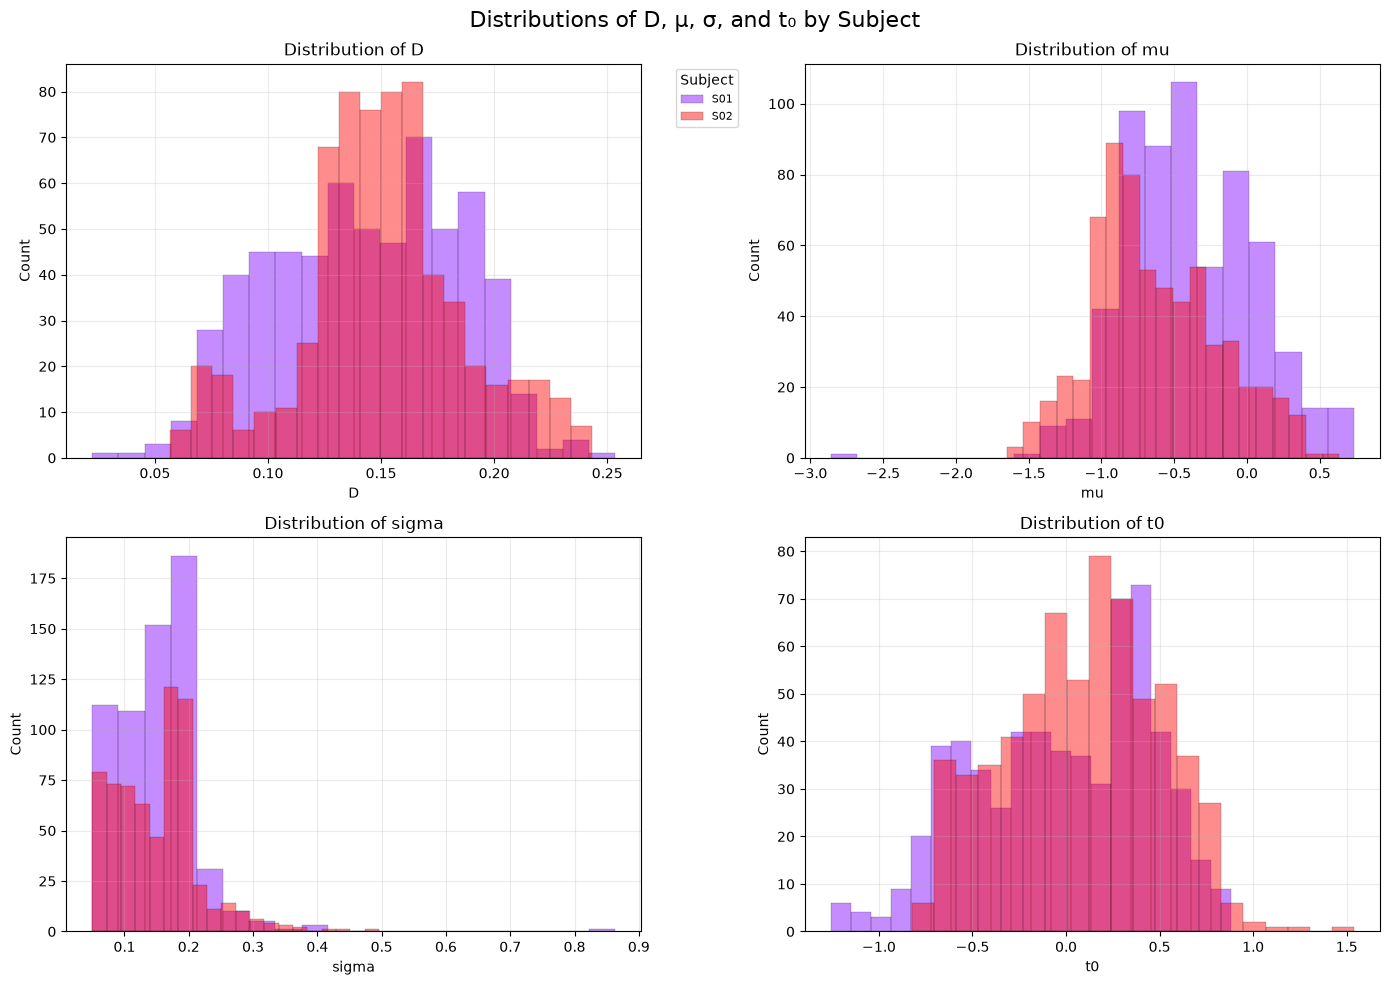

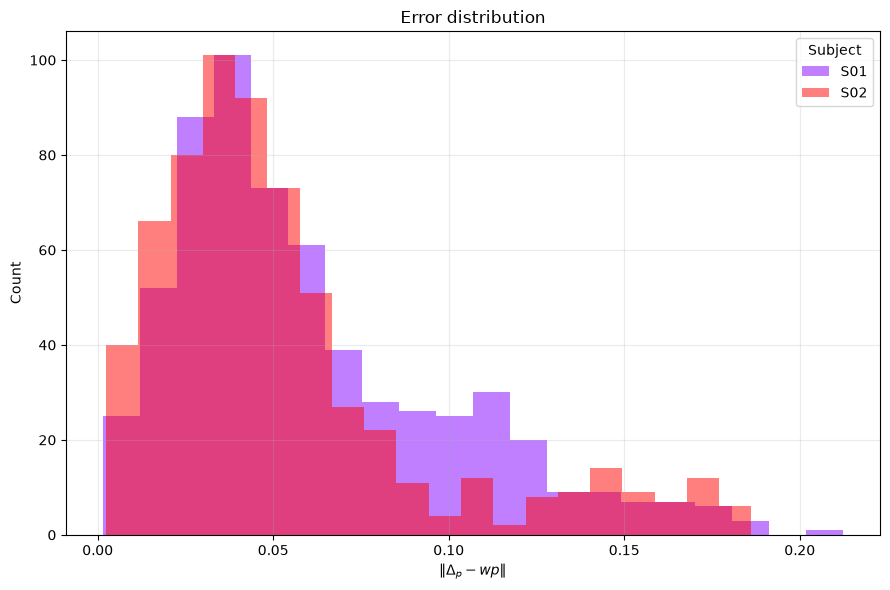

In [13]:
# Use the processed database and compute D from delta_p when it is not already available.
plot_data = final_database.copy()

if "D" not in plot_data.columns:
  plot_data["D"] = plot_data["delta_p"].apply(
    lambda v: np.linalg.norm(np.asarray(v, dtype=np.float32))
  )

metrics = ["D", "mu", "sigma", "t0"]
subjects = sorted(plot_data["subject"].dropna().unique())
colors = plt.cm.rainbow(np.linspace(0, 1, len(subjects)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, metric in zip(axes, metrics):
  for subject, color in zip(subjects, colors):
    values = plot_data.loc[
      plot_data["subject"] == subject, metric
    ].dropna()

    ax.hist(
      values,
      bins=20,
      alpha=0.45,
      color=color,
      label=subject,
      edgecolor="black",
      linewidth=0.3,
    )

  ax.set_title(f"Distribution of {metric}")
  ax.set_xlabel(metric)
  ax.set_ylabel("Count")
  ax.grid(alpha=0.25)

axes[0].legend(
  title="Subject",
  bbox_to_anchor=(1.05, 1),
  loc="upper left",
  fontsize=8,
)

fig.suptitle("Distributions of D, μ, σ, and t₀ by Subject", fontsize=16)
plt.tight_layout()
plt.show()

plot_data["delta_p_wp_distance"] = plot_data.apply(
  lambda row: np.linalg.norm(
    np.asarray(row["delta_p"], dtype=np.float32)
    - np.asarray(row["wp"], dtype=np.float32)
  ),
  axis=1,
)

plt.figure(figsize=(9, 6))
for subject, color in zip(subjects, colors):
  values = plot_data.loc[
    plot_data["subject"] == subject, "delta_p_wp_distance"
  ].dropna()
  plt.hist(values, bins=20, alpha=0.5, color=color, label=subject)

plt.title("Error distribution")
plt.xlabel(r"$\|\Delta_p - wp\|$")
plt.ylabel("Count")
plt.grid(alpha=0.25)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

In [14]:
def vectors(frame, columns):
    return frame[columns].to_numpy(dtype=np.float32)

f32 = lambda a: np.asarray(a, dtype=np.float32)
data = final_database.copy()
formatted_data = pd.DataFrame({
    "wp": data["wp"],
    "wp_n": data["wp_n"],

    't0': list(f32(data['t0'])),
    'mu': list(f32(data['mu'])),
    'sigma': list(f32(data['sigma'])),

    'delta_p': data['delta_p'],
    'u_s': data['u_s'],
    'lambda_s': list(f32(data['lambda_s'])),
    'u_e': data['u_e'],
    'lambda_e': list(f32(data['lambda_e'])),

    't0_previous': list(f32(data['t0_previous'])),
    'mu_previous': list(f32(data['mu_previous'])),
    'sigma_previous': list(f32(data['sigma_previous'])),

    'subject': data['subject'],

})

formatted_data.head(10)

,wp,wp_n,t0,mu,sigma,delta_p,u_s,lambda_s,u_e,lambda_e,t0_previous,mu_previous,sigma_previous,subject
0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.642,0.153586,0.081711,"(0.14432144911670713, 0.06706838777927969, -0....","(0.9700483590091524, -0.2362519799379216, -0.0...",0.033370,"(0.2207562287564279, 0.9723969202238582, 0.075...",0.060210,NaN,NaN,NaN,S01
1,"[-0.14432146, 0.010931611, 0.012907238]","[-0.14432146, 0.010931611, 0.012907238]",0.294,-0.680848,0.182883,"(-0.1601478798257494, 0.08058505759973233, 0.0...","(-0.11884807041176297, 0.9879203984706839, 0.0...",0.068837,"(-0.9995785545264549, -0.02794476200820617, -0...",0.028732,-0.642,0.153586,0.081711,S01
2,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.240,-0.295600,0.138464,"(0.17056932130531882, 0.060494883362214404, -0...","(0.9847971472621677, -0.14958862537256923, 0.0...",0.026934,"(0.2871657581466427, 0.9575315413899897, 0.025...",0.066373,NaN,NaN,NaN,S01
3,"[-0.17056932, 0.017505117, 0.0053005563]","[-0.17056932, 0.017505117, 0.0053005563]",0.254,-0.580980,0.181585,"(-0.1849465689957268, 0.08243738313551789, -0....","(-0.08052890672792198, 0.9967437579898101, 0.0...",0.067422,"(-0.9705440395631034, -0.14308890984005446, 0....",0.058829,-0.240,-0.295600,0.138464,S01
4,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.618,0.107258,0.089652,"(0.14651876924533025, 0.06354141825907234, -0....","(0.9240205645838965, -0.3809984546984475, -0.0...",0.039859,"(0.19773841109482437, 0.9793110041111769, 0.04...",0.060777,NaN,NaN,NaN,S01
5,"[-0.14651877, 0.014458582, 0.013137617]","[-0.14651877, 0.014458582, 0.013137617]",0.258,-0.637087,0.184532,"(-0.16339250686681103, 0.08152290983928898, -0...","(-0.1330558245604108, 0.9899640491792803, 0.04...",0.063654,"(-0.9911391905463522, -0.12794444918787315, 0....",0.047799,-0.618,0.107258,0.089652,S01
6,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.180,-0.179336,0.150746,"(0.1635246554743523, 0.09110137377997211, 0.00...","(0.9644672797467375, -0.24413089289483317, 0.1...",0.040779,"(-0.20467495764630866, 0.9723170004232107, 0.1...",0.102007,NaN,NaN,NaN,S01
7,"[-0.16352466, -0.013101369, -0.0073017725]","[-0.16352466, -0.013101369, -0.0073017725]",0.488,-0.748430,0.200368,"(-0.16491086080623596, 0.05145149352032921, -0...","(-0.41841362029017637, 0.9057304711246873, 0.0...",0.076566,"(-0.9827653840344551, -0.08492501585803988, -0...",0.001607,-0.180,-0.179336,0.150746,S01
8,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.510,-0.122554,0.117714,"(0.15131736303067078, 0.051101890107903565, -0...","(0.9321635574676818, -0.3620058286494098, 0.00...",0.037631,"(0.3297911552546242, 0.9402459457217266, -0.08...",0.055750,NaN,NaN,NaN,S01
9,"[-0.15131736, 0.026898112, 0.012890997]","[-0.15131736, 0.026898112, 0.012890997]",0.118,-0.534845,0.175022,"(-0.18824215773834907, 0.07496334151829634, -0...","(-0.1376421086725083, 0.9816918142346144, -0.1...",0.067380,"(-0.9427949527801668, -0.30160486974351186, 0....",0.054437,-0.510,-0.122554,0.117714,S01


## Training

In [15]:
KEYS = ["wp", "wp_n", 
        "prev_t0", "prev_mu", "prev_sigma",
        "t0", "mu", "sigma",
        "u_s", "lambda_s", "u_e", "lambda_e", "delta_p"]
TARGET_KEYS = ["t0", "mu", "sigma", "lambda_e", "u_e", "delta_p"]

stroke_dataset = StrokeDataset(formatted_data)
stroke_loader = StrokeDataLoader(stroke_dataset, batch_size=32, shuffle=True)

# ---- split by subject ----
subjects = formatted_data["subject"].unique()
rng = np.random.default_rng(0)
rng.shuffle(subjects)
val_subjects = set(subjects[: max(1, int(0.15 * len(subjects)))])
is_val = formatted_data["subject"].isin(val_subjects)

train_ds = StrokeDataset(formatted_data[~is_val].reset_index(drop=True))
val_ds = StrokeDataset(formatted_data[is_val].reset_index(drop=True))
train_loader = StrokeDataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = StrokeDataLoader(val_ds, batch_size=32, shuffle=False)


# ---- standardization ----
@torch.no_grad()
def compute_stats(loader, keys=KEYS, eps=1e-8):
    chunks = {k: [] for k in keys}
    for batch in loader:
        for k in keys:
            chunks[k].append(batch[k].float().reshape(batch[k].size(0), -1))
    stats = {}
    for k, v in chunks.items():
        v = torch.cat(v)
        stats[k] = (v.mean(0), v.std(0).clamp_min(eps))
    return stats


def normalize_batch(batch, stats, device):
    out = {}
    for k, (m, s) in stats.items():
        x = batch[k].float().to(device).reshape(batch[k].size(0), -1)
        out[k] = (x - m.to(device)) / s.to(device)
    return out


@torch.no_grad()
def stack_targets(loader, stats):
    rows = []
    for b in loader:
        nb = normalize_batch(b, stats, "cpu")
        rows.append(torch.cat([nb[k] for k in TARGET_KEYS], dim=-1))
    return torch.cat(rows)


stats = compute_stats(train_loader)

# ---- model ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GenerativeModel(
    input_dim=6, embedding_dim=64, LSTM_dim=128, LSTM_count=1,
    output_dim=9, mixture_components=8, recur_dim=5,
).to(device)
model.set_weights(stack_targets(train_loader, stats).to(device))

/tmp/ipykernel_65721/2970582680.py:13: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(subjects)


KeyError: 'prev_delta_p'

In [ ]:
# 1) closed-form vs explicit Fisher: the parameter gradients must coincide
batch = normalize_batch(next(iter(train_loader)), stats, device)
grads = {}
for mode in ("closed_form", "explicit"):
    model.zero_grad()
    ngem_loss(model, batch, device, fisher_mode=mode).backward()
    grads[mode] = torch.cat([p.grad.flatten() for p in model.parameters() if p.grad is not None])
rel_err = (grads["closed_form"] - grads["explicit"]).norm() / grads["explicit"].norm()
print(f"relative gradient difference: {rel_err:.2e}")   # expect ~1e-4 or lower

# 2) unconditional baseline: single full-covariance Gaussian fitted on the train targets
from torch.distributions import MultivariateNormal
tr_t, va_t = stack_targets(train_loader, stats), stack_targets(val_loader, stats)
cov = torch.cov(tr_t.T) + 1e-6 * torch.eye(tr_t.size(1))
baseline_nll = -MultivariateNormal(tr_t.mean(0), cov).log_prob(va_t).mean().item()
print(f"baseline val NLL: {baseline_nll:.3f}")

In [ ]:

def run_epoch(loader, train, optimizer=None, clip=5.0, **loss_kw):
    model.train(train)
    total, n = 0.0, 0
    for batch in loader:
        batch = normalize_batch(batch, stats, device)
        with torch.set_grad_enabled(train):
            loss, nll = ngem_loss(model, batch, device, return_nll=True, **loss_kw)
        if train:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
        bs = batch["t0"].size(0)
        total += nll.item() * bs
        n += bs
    return total / n


#optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
#scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=10)
#
#best_val, patience, bad_epochs = float("inf"), 30, 0
#for epoch in range(500):
#    train_nll = run_epoch(train_loader, train=True, optimizer=optimizer)
#    val_nll = run_epoch(val_loader, train=False)
#    scheduler.step(val_nll)
#    print(f"epoch {epoch:3d} | train NLL {train_nll:8.3f} | val NLL {val_nll:8.3f} "
#          f"| lr {optimizer.param_groups[0]['lr']:.1e}")
#
#    if val_nll < best_val:
#        best_val, bad_epochs = val_nll, 0
#        torch.save({"model": model.state_dict(), "stats": stats}, "best_ngem.pt")
#    else:
#        bad_epochs += 1
#        if bad_epochs >= patience:
#            break

In [ ]:
def all_z(loader):
    chunks = {k: [] for k in KEYS}
    for b in loader:
        nb = normalize_batch(b, stats, "cpu")
        for k in KEYS:
            chunks[k].append(nb[k])
    return {k: torch.cat(v) for k, v in chunks.items()}

for name, loader in (("train", train_loader), ("val", val_loader)):
    z = all_z(loader)
    print(name, {k: round(v.abs().max().item(), 1) for k, v in z.items()})

In [ ]:
import torch.nn.functional as F
from torch.distributions import MultivariateNormal

def mdn_nll_loss(model, batch, device, return_nll=True, **_):
    target = torch.cat([batch[k] for k in TARGET_KEYS], dim=-1).to(device)
    x = torch.cat([batch["wp"], batch["wp_n"]], dim=-1).to(device)
    prev = torch.cat([batch[k] for k in
                      ("prev_t0", "prev_mu", "prev_sigma", "prev_theta", "prev_psi")], dim=-1).to(device)
    means, scale_tril, logits = model(x, prev_output=prev)
    log_prob = MultivariateNormal(means, scale_tril=scale_tril).log_prob(target.unsqueeze(1))
    nll = -torch.logsumexp(F.log_softmax(logits, dim=-1) + log_prob, dim=-1).mean()
    return nll, nll.detach()

In [ ]:
@torch.no_grad()
def diagnose(batch):
    model.eval()
    x = torch.cat([batch["wp"], batch["wp_n"]], dim=-1)
    prev = torch.cat([batch[k] for k in
                      ("prev_t0", "prev_mu", "prev_sigma", "prev_theta", "prev_psi")], dim=-1)
    means, L, logits = model(x, prev_output=prev)
    print(f"max|mean| {means.abs().max():.2f} | min diag(L) {L.diagonal(dim1=-2, dim2=-1).min():.2e} "
          f"| max diag(L) {L.diagonal(dim1=-2, dim2=-1).max():.2e} "
          f"| min pi {logits.softmax(-1).min():.2e}")

In [ ]:
@torch.no_grad()
def output_summary(batch):
    x = torch.cat([batch["wp"], batch["wp_n"]], dim=-1)
    prev = torch.cat([batch[k] for k in
                      ("prev_t0", "prev_mu", "prev_sigma", "prev_theta", "prev_psi")], dim=-1)
    means, L, logits = model(x, prev_output=prev)
    diag = L.diagonal(dim1=-2, dim2=-1)
    return (f"max|mean| {means.abs().max():8.2f} | diag(L) min {diag.min():.1e} "
            f"max {diag.max():.1e} | min pi {logits.softmax(-1).min():.1e}")


def debug_run(loss_fn, steps=400, lr=1e-4, clip=1.0, log_every=20, **loss_kw):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    step = 0
    model.train()
    while step < steps:
        for batch in train_loader:
            batch = normalize_batch(batch, stats, device)
            loss, nll = loss_fn(model, batch, device, return_nll=True, **loss_kw)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            if not (torch.isfinite(gnorm) and torch.isfinite(nll)):
                print(f"step {step}: non-finite (nll={nll.item()}, gnorm={gnorm.item()}) -> stop")
                return
            opt.step()
            if step % log_every == 0:
                print(f"step {step:4d} | nll {nll.item():9.3f} | gnorm {gnorm.item():9.2f} | "
                      + output_summary(batch))
            step += 1
            if step >= steps:
                break

In [ ]:
debug_run(mdn_nll_loss, steps=2500, lr=3e-5, clip=1.0, log_every=30)

In [ ]:
import numpy as np
import torch

TARGET_SIZES = {"t0": 1, "mu": 1, "sigma": 1, "p_m": 3, "p_e": 3}  # same order as the training target


def _z(name, value):
    """Standardize a raw value with the training statistics -> tensor [n, d] on device."""
    m, s = stats[name]
    v = torch.as_tensor(np.asarray(value), dtype=torch.float32).reshape(-1, m.numel())
    return ((v - m) / s).to(device)


@torch.no_grad()
def generate_strokes(source_row, n_samples=1, mode="sample"):
    """
    Generate stroke(s) conditioned on the fields of one dataset row.

    Args:
        source_row: row of the original dataframe (pd.Series) with the current/previous columns.
        n_samples:  number of strokes to generate.
        mode:       "sample" draws from the mixture; "best_component" takes the mean of the
                    most likely component (deterministic).
    Returns:
        list of Stroke objects.
    """
    def vec(base, suffix=""):
        return np.array([source_row[f"{base}_{a}{suffix}"] for a in "xyz"], dtype=np.float64)

    start, end = vec("start"), vec("end")
    prev_start, prev_mid, prev_end = vec("start", "_previous"), vec("mid", "_previous"), vec("end", "_previous")
    theta_prev, psi_prev = entry_angles(prev_start, prev_mid, prev_end)

    # same representation used in training
    x = torch.cat([_z("wp", start - prev_end), _z("wp_n", end - prev_end)], dim=-1)
    prev = torch.cat([
        _z("prev_t0", source_row["t0_previous"]),
        _z("prev_mu", source_row["mu_previous"]),
        _z("prev_sigma", source_row["sigma_previous"]),
        _z("prev_theta", theta_prev),
        _z("prev_psi", psi_prev),
    ], dim=-1)
    x, prev = x.repeat(n_samples, 1), prev.repeat(n_samples, 1)

    model.eval()
    if mode == "sample":
        y = model.sample(x, prev_output=prev)                       # [n, 9], standardized
    elif mode == "best_component":
        means, _, logits = model(x, prev_output=prev)
        y = means[torch.arange(means.size(0)), logits.argmax(-1)]
    else:
        raise ValueError("mode must be 'sample' or 'best_component'")

    # de-standardize each target block
    out, i = {}, 0
    for key, d in TARGET_SIZES.items():
        m, s = stats[key]
        out[key] = (y[:, i:i + d].cpu() * s + m).numpy().astype(np.float64)
        i += d

    strokes = []
    for j in range(n_samples):
        stroke = Stroke(
            D=0.0,
            mu=float(out["mu"][j, 0]),
            sigma=max(float(out["sigma"][j, 0]), 1e-6),   # see note on the sigma convention
            t0=float(out["t0"][j, 0]),
            start=start,
            mid=prev_end + out["p_m"][j],                  # p_m, p_e were relative to previous_end
            end=prev_end + out["p_e"][j],
        )
        stroke.D = stroke.arc_length                       # D is derived from the geometry
        strokes.append(stroke)
    return strokes

In [ ]:
idx = 468                                     # row index in `data`
source_row = data.iloc[idx]                   # better: pick it from the validation rows
generated_stroke = generate_strokes(source_row, mode="best_component")[0]

# consistency check: the arc must end where the generated end point is
gap = np.linalg.norm(generated_stroke.arc.point(1.0)[0] - generated_stroke.end)
print(f"arc end vs generated end: {gap:.2e}")

# Visualize the generated stroke and waypoints.
delta = np.linspace(0.0, 1.0, 200)
generated_points = generated_stroke.arc.point(delta)

generated_waypoints = np.vstack([
    generated_stroke.start,
    generated_stroke.mid,
    generated_stroke.end,
])

target_waypoints = np.array([
    [source_row["start_x"], source_row["start_y"], source_row["start_z"]],
    [source_row["mid_x"], source_row["mid_y"], source_row["mid_z"]],
    [source_row["end_x"], source_row["end_y"], source_row["end_z"]],
])

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(*generated_points.T, linewidth=2, label="Generated stroke")
ax.plot(
    *target_waypoints.T,
    "--",
    color="black",
    linewidth=1.5,
    label="Target stroke",
)

ax.scatter(
    *generated_waypoints.T,
    color=["green", "orange", "red"],
    s=70,
    label="Generated waypoints",
)

ax.scatter(
    *target_waypoints.T,
    color="black",
    marker="x",
    s=70,
    label="Target waypoints",
)

for label, point in zip(("Start", "Mid", "End"), generated_waypoints):
    ax.text(*point, f"Generated {label}")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Generated Stroke and Waypoints")
ax.legend()
plt.tight_layout()
plt.show()

original_arc = Arc.from_three_points(
    target_waypoints[0],
    target_waypoints[1],
    target_waypoints[2],
)
original_points = original_arc.point(delta)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(*original_points.T, linewidth=2, label="Original stroke")
ax.scatter(
    *target_waypoints.T,
    color=["green", "orange", "red"],
    s=70,
    label="Original waypoints",
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Original Stroke")
ax.legend()
plt.tight_layout()
plt.show()